# QFF 2026 Phase 2 — PS-O1: Max-Cut with QAOA

Runs top to bottom with `Run All` (about 1 to 3 minutes on a laptop CPU). All required runs use the **official settings** from `qff_phase2.py` (basis `rz, sx, x, cx`, `optimization_level=1`, SABRE, `seed_transpiler=42`, `seed_simulator=42`, 4096 shots, official noise). Initialization seeds are **0, 1, 2, 3, 4**.

**Contents**
1. Setup and processors
2. Formulation: Max-Cut, QUBO, cost Hamiltonian
3. Classical optimum and random baseline
4. QAOA (p = 1): circuit, exact simulator, optimisation over 5 seeds
5. Benchmark on Processors A, B, D (ideal and noisy) and resource metrics
6. Consistency over seeds
7. Figures
8. Additional experiment: p = 2 (optional)
9. Objective 1: Bell-state verification on Processor D

## 1. Setup and processors

In [1]:
import json, csv, itertools, os, time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qff_phase2 import (PROCESSOR_A, PROCESSOR_B, load_processor, validate_processor_d,
                        circuit_metrics, transpile_for, simulator, bell_experiment,
                        counts_to_x, coupling_map_from_edges, SHOTS, SEED)

T0 = time.time()
for d in ("results/tables", "results/figures"):
    os.makedirs(d, exist_ok=True)

inst = json.load(open("data/instance.json"))["PS-O1"]       # locked instance
EDGES = [tuple(e) for e in inst["weighted_edges"]]           # (i, j, w)
N = inst["num_vertices"]
SEEDS = inst["initialization_seeds"]                         # [0, 1, 2, 3, 4]
W_TOTAL = sum(w for _, _, w in EDGES)
print("N =", N, "| edges =", len(EDGES), "| total weight =", W_TOTAL, "| seeds =", SEEDS)

A = load_processor("processors/processor_A.json")
B = load_processor("processors/processor_B.json")
D = load_processor("processors/processor_D.json")
assert sorted(A["edges"]) == sorted(PROCESSOR_A["edges"]) and A["num_qubits"] == 5
assert sorted(B["edges"]) == sorted(PROCESSOR_B["edges"]) and B["num_qubits"] == 9
print("Processor D rule check:", validate_processor_d(D, required_qubits=N) or "OK")
print("D:", D["num_qubits"], "qubits,", len(D["edges"]), "edges")

N = 6 | edges = 9 | total weight = 27 | seeds = [0, 1, 2, 3, 4]
Processor D rule check: OK
D: 6 qubits, 9 edges


## 2. Formulation

Binary variable $x_i \in \{0,1\}$ is the group of vertex $i$ (vertex $i$ = qubit $i$). An edge $(i,j)$ with weight $w_{ij}$ is cut iff $x_i \ne x_j$:

$$C(x)=\sum_{(i,j)\in E} w_{ij}\,(x_i+x_j-2x_ix_j),\qquad \min_x\; -C(x).$$

**QUBO.** Since $x_i^2=x_i$, $-C(x)=x^{\top}Qx$ with a symmetric $Q$:

$$Q_{ii}=-\sum_{j}w_{ij}\ (\text{weighted degree}),\qquad Q_{ij}=Q_{ji}=w_{ij}\ \ (i\ne j).$$

**Cost Hamiltonian.** With $x_i=(1-Z_i)/2$, $x_i+x_j-2x_ix_j=(1-Z_iZ_j)/2$, so

$$-C = H_C-\tfrac{1}{2}W_{\text{tot}},\qquad H_C=\sum_{(i,j)\in E}\tfrac{w_{ij}}{2}\,Z_iZ_j .$$

**QAOA, depth p.** $|\psi(\boldsymbol\gamma,\boldsymbol\beta)\rangle=\prod_{l=1}^{p}e^{-i\beta_l\sum_i X_i}\,e^{-i\gamma_l H_C}\,|+\rangle^{\otimes n}$.
In the circuit, $e^{-i\gamma w Z_iZ_j/2}$ is `RZZ(γ·w)` and $e^{-i\beta X}$ is `RX(2β)`. We minimise $\langle H_C\rangle$, equivalently maximise the expected cut $\langle C\rangle$.

## 3. Classical optimum, optimal set and random baseline

In [2]:
def cut_value(x):
    return sum(w * (x[i] + x[j] - 2 * x[i] * x[j]) for i, j, w in EDGES)

ALL_X = list(itertools.product([0, 1], repeat=N))
CUTS = {x: cut_value(x) for x in ALL_X}
C_STAR = max(CUTS.values())
OPT_SET = {x for x, v in CUTS.items() if v == C_STAR}      # a cut and its complement both count
R_RANDOM = float(np.mean(list(CUTS.values())) / C_STAR)     # uniform-random baseline for r
P_OPT_RANDOM = len(OPT_SET) / 2 ** N                        # uniform-random baseline for P_opt

# QUBO matrix and check x^T Q x = -C(x) for all 64 bitstrings
Q = np.zeros((N, N))
for i, j, w in EDGES:
    Q[i, i] -= w; Q[j, j] -= w
    Q[i, j] += w; Q[j, i] += w
assert all(abs(np.array(x) @ Q @ np.array(x) + CUTS[x]) < 1e-9 for x in ALL_X)

print("QUBO matrix Q:\n", Q.astype(int))
print("C* =", C_STAR, "| optimal set:", sorted(OPT_SET))
print(f"random baseline: r = {R_RANDOM:.4f}, P_opt = {P_OPT_RANDOM:.5f}")

QUBO matrix Q:
 [[ -9   0   1   4   4   0]
 [  0  -6   0   0   3   3]
 [  1   0  -7   5   1   0]
 [  4   0   5 -15   4   2]
 [  4   3   1   4 -12   0]
 [  0   3   0   2   0  -5]]
C* = 22 | optimal set: [(0, 0, 1, 0, 1, 1), (1, 1, 0, 1, 0, 0)]
random baseline: r = 0.6136, P_opt = 0.03125


## 4. QAOA

We build the circuit with Qiskit, and use an **exact NumPy statevector simulator** of the same circuit as the cost function for the classical optimiser (no shot noise in the optimisation). A cell below checks that the two agree.

Optimiser: **COBYLA**, `maxiter = 200`, cost evaluated with the **exact statevector** (ideal). Starting angles: `numpy.random.default_rng(seed).uniform(0, pi)`, γ drawn first, then β. Optimisation is done **once in ideal simulation**; the same angles are then evaluated on A, B, D, ideal and noisy.

In [3]:
def qaoa_circuit(gammas, betas, measure=True):
    qc = QuantumCircuit(N)
    qc.h(range(N))
    for g, b in zip(gammas, betas):
        for i, j, w in EDGES:
            qc.rzz(g * w, i, j)          # exp(-i g w Z_i Z_j / 2)
        qc.rx(2 * b, range(N))           # exp(-i b X)
    if measure:
        qc.measure_all()
    return qc

# ---- exact NumPy simulator of the same circuit (little-endian: qubit i = bit i of the index)
CUT_K = np.array([cut_value(tuple((k >> i) & 1 for i in range(N))) for k in range(2 ** N)], float)
H_DIAG = W_TOTAL / 2 - CUT_K             # diagonal of H_C = sum (w/2) Z_i Z_j

def qaoa_state(gammas, betas):
    psi = np.ones(2 ** N, complex) / np.sqrt(2 ** N)
    for g, b in zip(gammas, betas):
        psi = psi * np.exp(-1j * g * H_DIAG)
        c, s = np.cos(b), -1j * np.sin(b)
        U = np.array([[c, s], [s, c]])
        t = psi.reshape((2,) * N)
        for i in range(N):
            ax = N - 1 - i
            t = np.moveaxis(np.tensordot(U, t, axes=([1], [ax])), 0, ax)
        psi = t.reshape(-1)
    return psi

def expected_cut(gammas, betas):
    return float(np.sum(np.abs(qaoa_state(gammas, betas)) ** 2 * CUT_K))

def optimise(p, seed, maxiter=200):
    rng = np.random.default_rng(seed)
    x0 = rng.uniform(0, np.pi, 2 * p)                 # first p = gamma, last p = beta
    res = minimize(lambda v: -expected_cut(v[:p], v[p:]), x0, method="COBYLA",
                   options={"maxiter": maxiter})
    return x0, res.x, -res.fun, res.nfev

# ---- check: Qiskit circuit == NumPy simulator
g_t, b_t = [0.7], [0.4]
sv = Statevector(qaoa_circuit(g_t, b_t, measure=False))
assert np.allclose(sv.probabilities(), np.abs(qaoa_state(g_t, b_t)) ** 2, atol=1e-9)
print("Qiskit circuit matches the NumPy statevector simulator.")

Qiskit circuit matches the NumPy statevector simulator.


In [4]:
# ---- p = 1, five seeded initialisations
P1 = {}
print(f"{'seed':>4} | {'gamma0':>7} {'beta0':>7} | {'gamma*':>8} {'beta*':>8} | {'E[cut]':>8} {'r(exact)':>9} {'nfev':>5}")
for s in SEEDS:
    x0, xo, val, nfev = optimise(1, s)
    P1[s] = dict(x0=x0, g=[xo[0]], b=[xo[1]], val=val, nfev=nfev)
    print(f"{s:>4} | {x0[0]:7.3f} {x0[1]:7.3f} | {xo[0]:8.3f} {xo[1]:8.3f} | {val:8.4f} {val / C_STAR:9.4f} {nfev:>5}")

BEST_SEED = max(P1, key=lambda s: P1[s]["val"])
G_BEST, B_BEST = P1[BEST_SEED]["g"], P1[BEST_SEED]["b"]
print(f"\nBest seed = {BEST_SEED}: gamma = {G_BEST[0]:.4f}, beta = {B_BEST[0]:.4f}, "
      f"exact r = {P1[BEST_SEED]['val'] / C_STAR:.4f}")
qc_best = qaoa_circuit(G_BEST, B_BEST)
print(qc_best.draw(fold=120))

seed |  gamma0   beta0 |   gamma*    beta* |   E[cut]  r(exact)  nfev
   0 |   2.001   0.848 |    2.960   -0.407 |  15.5515    0.7069    43
   1 |   1.608   2.986 |    2.960    4.305 |  15.5515    0.7069    97


   2 |   0.822   0.938 |    2.960   -0.407 |  15.5515    0.7069    41


   3 |   0.269   0.744 |   -0.168    0.333 |  17.7128    0.8051    41


   4 |   2.963   1.606 |    4.708    0.850 |  15.5324    0.7060    54

Best seed = 3: gamma = -0.1680, beta = 0.3327, exact r = 0.8051
        ┌───┐                                             ┌─────────────┐                                             »
   q_0: ┤ H ├─■──────────────■──────────────■─────────────┤ Rx(0.66536) ├─────────────────────────────────────────────»
        ├───┤ │              │              │             └─────────────┘                              ┌─────────────┐»
   q_1: ┤ H ├─┼──────────────┼──────────────┼─────────────────────────────■──────────────■─────────────┤ Rx(0.66536) ├»
        ├───┤ │ZZ(-0.16801)  │              │                             │              │             └─────────────┘»
   q_2: ┤ H ├─■──────────────┼──────────────┼──────────────■──────────────┼──────────────┼──────────────■─────────────»
        ├───┤                │ZZ(-0.67205)  │              │ZZ(-0.84006)  │              │              │             »
   q_3: ┤ H ├────────────

## 5. Benchmark on Processors A, B and D

Metrics are measured on the bound QAOA circuit **with measurements** using `circuit_metrics()`. Quality metrics come from **4096 shots**, ideal and noisy, with the best angles from section 4:

- $r=\overline{C}_{\text{shots}}/C^*$ (primary), $r_{\text{best}}=\max C/C^*$, $P_{\text{opt}}$ = fraction of shots in the optimal set.

Processor A has 5 qubits and the circuit needs 6, so it is reported as *not executable* (capacity rule). The instance is not shrunk.

In [5]:
def sample_stats(counts):
    tot = sum(counts.values())
    xs = {k: counts_to_x(k) for k in counts}
    mean_cut = sum(cut_value(xs[k]) * v for k, v in counts.items()) / tot
    best_key = max(counts, key=lambda k: (cut_value(xs[k]), counts[k]))
    best_cut = cut_value(xs[best_key])
    p_opt = sum(v for k, v in counts.items() if xs[k] in OPT_SET) / tot
    return dict(r=mean_cut / C_STAR, mean_cut=mean_cut, best_cut=best_cut,
                r_best=best_cut / C_STAR, p_opt=p_opt, best_x=xs[best_key])

def run_on(qc, P, noisy):
    t = transpile_for(qc, P)                                  # official transpilation
    counts = simulator(noisy, P).run(t, shots=SHOTS).result().get_counts()
    return sample_stats(counts)

PROCS = [("A", A), ("B", B), ("D", D)]
METRICS = {k: circuit_metrics(qc_best, P) for k, P in PROCS}
RES = {}                     # (proc, cond) -> stats
for k, P in PROCS:
    if not METRICS[k]["executable"]:
        continue
    for cond in ("ideal", "noisy"):
        RES[(k, cond)] = run_on(qc_best, P, noisy=(cond == "noisy"))

# ---- required results.csv (kit Section 9 format)
HEADER = ["problem_id", "processor", "condition", "executable", "logical_qubits", "physical_qubits",
          "logical_cx", "cx", "depth", "two_q_depth", "swaps", "cx_overhead", "shots",
          "quality_metric", "quality_value", "p_opt", "classical_optimum", "random_baseline"]
rows = []
for k, P in PROCS:
    m = METRICS[k]
    for cond in ("ideal", "noisy"):
        if not m["executable"]:
            rows.append(["PS-O1", k, cond, "false", N, P["num_qubits"]] + [""] * 12)
        else:
            s = RES[(k, cond)]
            rows.append(["PS-O1", k, cond, "true", m["logical_qubits"], m["physical_qubits"],
                         m["logical_cx"], m["cx"], m["depth"], m["two_q_depth"], m["swaps"],
                         m["cx_overhead"], SHOTS, "approx_ratio", round(s["r"], 4),
                         round(s["p_opt"], 4), C_STAR, round(R_RANDOM, 4)])
with open("results/tables/results.csv", "w", newline="") as f:
    csv.writer(f).writerows([HEADER] + rows)

# ---- extra detail (r_best, best cut, best partition)
with open("results/tables/results_detail.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["processor", "condition", "mean_cut", "best_cut", "r", "r_best", "p_opt",
                "best_partition", "random_r", "random_p_opt"])
    for (k, cond), s in RES.items():
        w.writerow([k, cond, round(s["mean_cut"], 3), s["best_cut"], round(s["r"], 4),
                    round(s["r_best"], 4), round(s["p_opt"], 4), "".join(map(str, s["best_x"])),
                    round(R_RANDOM, 4), round(P_OPT_RANDOM, 5)])

print(f"C* = {C_STAR} | random: r = {R_RANDOM:.4f}, P_opt = {P_OPT_RANDOM:.4f}\n")
print(f"{'proc':<4} {'cond':<6} {'best':>4} {'r':>7} {'r_best':>7} {'P_opt':>7}  best partition")
for (k, cond), s in RES.items():
    print(f"{k:<4} {cond:<6} {s['best_cut']:>4} {s['r']:7.4f} {s['r_best']:7.4f} {s['p_opt']:7.4f}  {''.join(map(str, s['best_x']))}")
print("A     ideal/noisy: not executable (needs 6 qubits, has 5)")

print("\nResource table (bound QAOA circuit, official transpilation)")
keys = ["logical_qubits", "physical_qubits", "logical_cx", "cx", "depth", "two_q_depth", "swaps", "cx_overhead"]
print(f"{'proc':<4} " + " ".join(f"{h:>14}" for h in keys))
for k, _ in PROCS:
    m = METRICS[k]
    if m["executable"]:
        print(f"{k:<4} " + " ".join(f"{m[h]:>14}" for h in keys))
    else:
        print(f"{k:<4} not executable: {m['reason']}")

C* = 22 | random: r = 0.6136, P_opt = 0.0312

proc cond   best       r  r_best   P_opt  best partition
B    ideal    22  0.8074  1.0000  0.1396  001011
B    noisy    22  0.7874  1.0000  0.1260  110100
D    ideal    22  0.8052  1.0000  0.1384  001011
D    noisy    22  0.7862  1.0000  0.1250  001011
A     ideal/noisy: not executable (needs 6 qubits, has 5)

Resource table (bound QAOA circuit, official transpilation)
proc logical_qubits physical_qubits     logical_cx             cx          depth    two_q_depth          swaps    cx_overhead
A    not executable: needs 6 qubits > 5
B                 6              9             18             21             37             17              1              3
D                 6              6             18             18             29             14              0              0


## 6. Consistency over the 5 seeds

Each seed gives its own optimised angles (section 4). We evaluate every one of them with 4096 shots on B and D, ideal and noisy, and report the mean and sample standard deviation (ddof = 1) of $r$. Seeds that converge to the same angles give the same $r$ (the spread then reflects how many different local optima COBYLA found).

In [6]:
SEED_ROWS = []
for s in SEEDS:
    qc_s = qaoa_circuit(P1[s]["g"], P1[s]["b"])
    row = dict(seed=s, exact_r=P1[s]["val"] / C_STAR)
    for k, P in (("B", B), ("D", D)):
        for cond in ("ideal", "noisy"):
            row[f"r_{k}_{cond}"] = run_on(qc_s, P, noisy=(cond == "noisy"))["r"]
    SEED_ROWS.append(row)

cols = ["exact_r", "r_B_ideal", "r_B_noisy", "r_D_ideal", "r_D_noisy"]
print(f"{'seed':>4} " + " ".join(f"{c:>10}" for c in cols))
for r_ in SEED_ROWS:
    print(f"{r_['seed']:>4} " + " ".join(f"{r_[c]:10.4f}" for c in cols))
print("mean " + " ".join(f"{np.mean([r_[c] for r_ in SEED_ROWS]):10.4f}" for c in cols))
print(" std " + " ".join(f"{np.std([r_[c] for r_ in SEED_ROWS], ddof=1):10.4f}" for c in cols))

with open("results/tables/seeds.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["seed"] + cols)
    for r_ in SEED_ROWS:
        w.writerow([r_["seed"]] + [round(r_[c], 4) for c in cols])

seed    exact_r  r_B_ideal  r_B_noisy  r_D_ideal  r_D_noisy
   0     0.7069     0.7104     0.6981     0.7101     0.6991
   1     0.7069     0.7105     0.6981     0.7104     0.6990
   2     0.7069     0.7103     0.6982     0.7103     0.6990
   3     0.8051     0.8074     0.7874     0.8052     0.7862
   4     0.7060     0.7065     0.6930     0.7070     0.6955
mean     0.7264     0.7290     0.7150     0.7286     0.7157
 std     0.0440     0.0438     0.0405     0.0428     0.0394


## 7. Figures

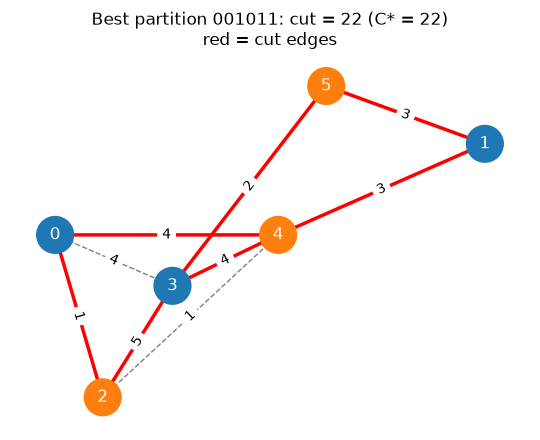

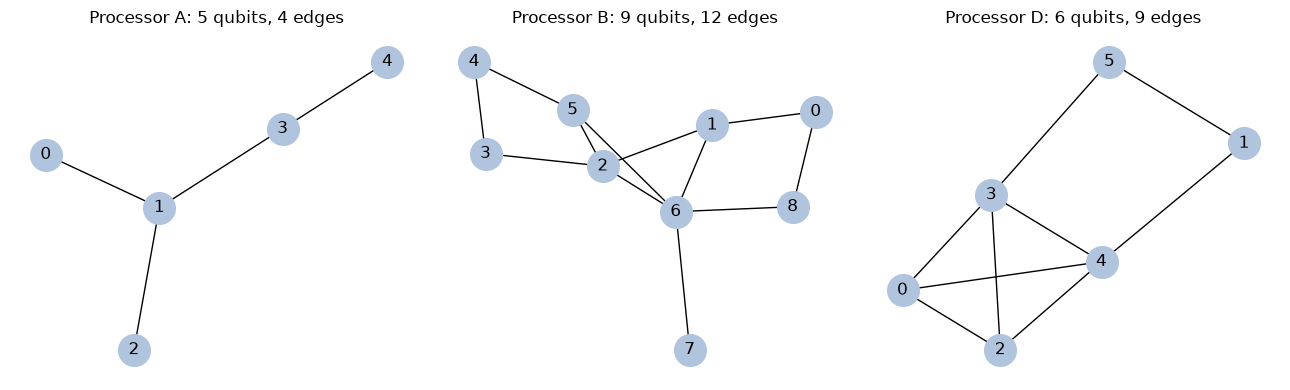

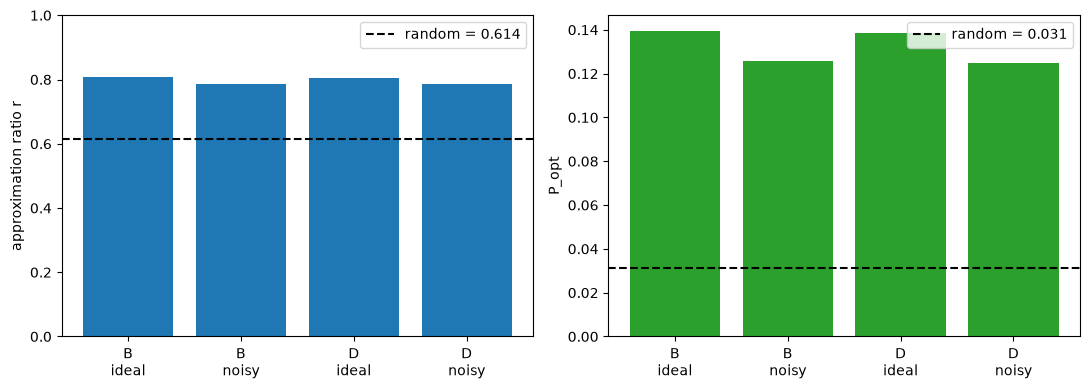

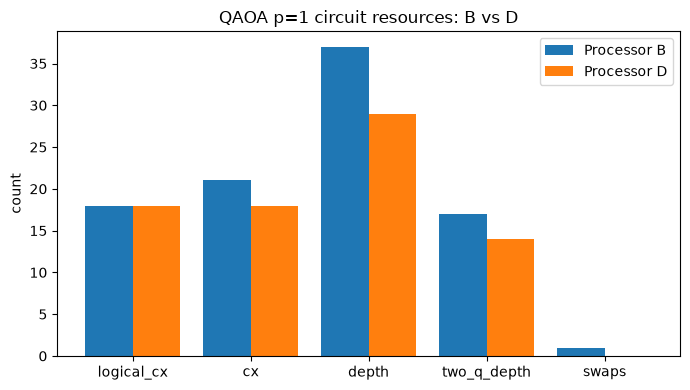

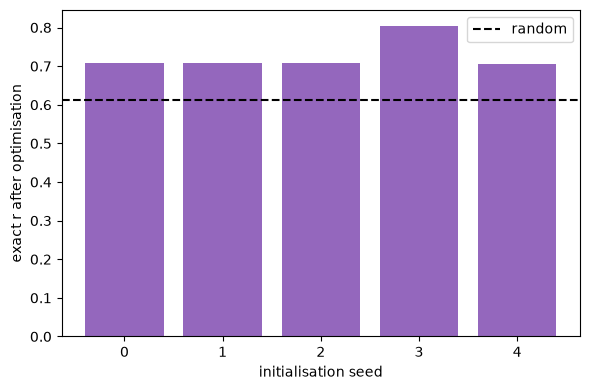

In [7]:
G = nx.Graph()
G.add_nodes_from(range(N))
G.add_weighted_edges_from(EDGES)
POS = nx.spring_layout(G, seed=SEED)

# ---- (a) weighted graph with the best partition (best sampled bitstring on D, ideal)
bx = RES[("D", "ideal")]["best_x"]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cut_edges = [(i, j) for i, j, _ in EDGES if bx[i] != bx[j]]
same_edges = [(i, j) for i, j, _ in EDGES if bx[i] == bx[j]]
nx.draw_networkx_nodes(G, POS, node_color=["tab:blue" if bx[i] == 0 else "tab:orange" for i in range(N)],
                       node_size=700, ax=ax)
nx.draw_networkx_labels(G, POS, font_color="white", ax=ax)
nx.draw_networkx_edges(G, POS, edgelist=cut_edges, edge_color="red", width=2.5, ax=ax)
nx.draw_networkx_edges(G, POS, edgelist=same_edges, edge_color="gray", style="dashed", ax=ax)
nx.draw_networkx_edge_labels(G, POS, edge_labels={(i, j): w for i, j, w in EDGES}, ax=ax)
ax.set_title(f"Best partition {''.join(map(str, bx))}: cut = {cut_value(bx)} (C* = {C_STAR})\nred = cut edges")
ax.axis("off")
plt.tight_layout(); plt.savefig("results/figures/maxcut_best_partition.png", dpi=150); plt.show()

# ---- (b) coupling graphs of A, B, D
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (k, P) in zip(axes, PROCS):
    g = nx.Graph(); g.add_nodes_from(range(P["num_qubits"])); g.add_edges_from(P["edges"])
    nx.draw(g, nx.spring_layout(g, seed=SEED), with_labels=True, node_color="lightsteelblue",
            node_size=520, ax=ax)
    ax.set_title(f"Processor {k}: {P['num_qubits']} qubits, {len(P['edges'])} edges")
plt.tight_layout(); plt.savefig("results/figures/processors_coupling_graphs.png", dpi=150); plt.show()

# ---- (c) quality: r and P_opt vs processor and condition, with random baseline
labels = [f"{k}\n{c}" for (k, c) in RES]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(labels, [s["r"] for s in RES.values()], color="tab:blue")
axes[0].axhline(R_RANDOM, color="k", ls="--", label=f"random = {R_RANDOM:.3f}")
axes[0].set_ylabel("approximation ratio r"); axes[0].legend(); axes[0].set_ylim(0, 1)
axes[1].bar(labels, [s["p_opt"] for s in RES.values()], color="tab:green")
axes[1].axhline(P_OPT_RANDOM, color="k", ls="--", label=f"random = {P_OPT_RANDOM:.3f}")
axes[1].set_ylabel("P_opt"); axes[1].legend()
plt.tight_layout(); plt.savefig("results/figures/quality_r_popt.png", dpi=150); plt.show()

# ---- (d) resources on B vs D
res_keys = ["logical_cx", "cx", "depth", "two_q_depth", "swaps"]
xpos = np.arange(len(res_keys))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(xpos - 0.2, [METRICS["B"][k] for k in res_keys], 0.4, label="Processor B")
ax.bar(xpos + 0.2, [METRICS["D"][k] for k in res_keys], 0.4, label="Processor D")
ax.set_xticks(xpos); ax.set_xticklabels(res_keys); ax.set_ylabel("count"); ax.legend()
ax.set_title("QAOA p=1 circuit resources: B vs D")
plt.tight_layout(); plt.savefig("results/figures/resources_B_vs_D.png", dpi=150); plt.show()

# ---- (e) r per seed
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([str(r_["seed"]) for r_ in SEED_ROWS], [r_["exact_r"] for r_ in SEED_ROWS], color="tab:purple")
ax.axhline(R_RANDOM, color="k", ls="--", label="random")
ax.set_xlabel("initialisation seed"); ax.set_ylabel("exact r after optimisation"); ax.legend()
plt.tight_layout(); plt.savefig("results/figures/seeds_exact_r.png", dpi=150); plt.show()

## 8. Additional experiment (optional): p = 2

Clearly **additional** (not part of the required rows). Same optimiser and seeds; angles are laid out as `[γ1, γ2, β1, β2]`, each drawn uniformly from [0, π]. Saved separately to `results/tables/results_p2_additional.csv`.

In [8]:
P2 = {}
for s in SEEDS:
    x0, xo, val, nfev = optimise(2, s)
    P2[s] = dict(g=list(xo[:2]), b=list(xo[2:]), val=val)
    print(f"p=2 seed {s}: E[cut] = {val:.4f}, exact r = {val / C_STAR:.4f}")
S2 = max(P2, key=lambda s: P2[s]["val"])
qc2 = qaoa_circuit(P2[S2]["g"], P2[S2]["b"])
print(f"\nbest p=2 seed = {S2}, exact r = {P2[S2]['val'] / C_STAR:.4f} (p=1 best: {P1[BEST_SEED]['val'] / C_STAR:.4f})")

p2_rows = []
for k, P in (("B", B), ("D", D)):
    m = circuit_metrics(qc2, P)
    for cond in ("ideal", "noisy"):
        s = run_on(qc2, P, noisy=(cond == "noisy"))
        p2_rows.append([2, k, cond, m["logical_cx"], m["cx"], m["depth"], m["swaps"],
                        round(s["r"], 4), round(s["r_best"], 4), round(s["p_opt"], 4),
                        round(P2[S2]["val"] / C_STAR, 4)])
        print(f"p=2 {k} {cond:<5}: CX={m['cx']:>3} depth={m['depth']:>3} swaps={m['swaps']:>2} "
              f"r={s['r']:.4f} r_best={s['r_best']:.4f} P_opt={s['p_opt']:.4f}")
with open("results/tables/results_p2_additional.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["p", "processor", "condition", "logical_cx", "cx", "depth", "swaps", "r", "r_best", "p_opt", "exact_r"])
    w.writerows(p2_rows)

p=2 seed 0: E[cut] = 15.9015, exact r = 0.7228


p=2 seed 1: E[cut] = 17.7822, exact r = 0.8083
p=2 seed 2: E[cut] = 15.8593, exact r = 0.7209


p=2 seed 3: E[cut] = 19.4172, exact r = 0.8826
p=2 seed 4: E[cut] = 16.7622, exact r = 0.7619

best p=2 seed = 3, exact r = 0.8826 (p=1 best: 0.8051)
p=2 B ideal: CX= 42 depth= 68 swaps= 2 r=0.8840 r_best=1.0000 P_opt=0.2290


p=2 B noisy: CX= 42 depth= 68 swaps= 2 r=0.8408 r_best=1.0000 P_opt=0.1897
p=2 D ideal: CX= 36 depth= 52 swaps= 0 r=0.8823 r_best=1.0000 P_opt=0.2312
p=2 D noisy: CX= 36 depth= 52 swaps= 0 r=0.8428 r_best=1.0000 P_opt=0.1934


## 9. Objective 1: Bell-state verification on Processor D

$|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$ is prepared with H on qubit 0 then CX(0→1) and measured in the ZZ, XX, YY bases (4096 shots each), using the organizer's `bell_experiment()`. Fidelity $F=(1+\langle XX\rangle-\langle YY\rangle+\langle ZZ\rangle)/4$.

Two physical pairs on D: an **adjacent** pair (distance 1) and the **farthest** pair (largest distance in D's coupling graph). Each pair is run ideal and noisy, giving 2 × 2 × 3 = 12 circuits.

In [9]:
cmD = coupling_map_from_edges(D["edges"], D["num_qubits"])
all_pairs = list(itertools.combinations(range(D["num_qubits"]), 2))
near_pair = tuple(D["edges"][0])                                     # a physically connected pair
far_pair = max(all_pairs, key=lambda pr: cmD.distance(*pr))          # farthest pair in D
print("adjacent pair:", near_pair, "distance", cmD.distance(*near_pair))
print("farthest pair:", far_pair, "distance", cmD.distance(*far_pair), "(diameter of D)")

BELL = []
for pair in (near_pair, far_pair):
    for noisy in (False, True):
        BELL.append(bell_experiment(D, pair, noisy))

with open("results/tables/bell.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["pair", "pair_distance", "condition", "cx_after_transpile", "XX", "XX_se", "YY", "YY_se",
                "ZZ", "ZZ_se", "F", "F_se"])
    for r_ in BELL:
        w.writerow(["-".join(map(str, r_["pair"])), r_["pair_distance"], "noisy" if r_["noisy"] else "ideal",
                    r_["cx"], round(r_["XX"], 4), round(r_["XX_se"], 4), round(r_["YY"], 4),
                    round(r_["YY_se"], 4), round(r_["ZZ"], 4), round(r_["ZZ_se"], 4),
                    round(r_["fidelity"], 4), round(r_["fidelity_se"], 4)])

print(f"\n{'pair':<6} {'dist':>4} {'cond':<6} {'CX':>3} {'<XX>':>14} {'<YY>':>14} {'<ZZ>':>14} {'F':>14}")
for r_ in BELL:
    print(f"{'-'.join(map(str, r_['pair'])):<6} {r_['pair_distance']:>4} {'noisy' if r_['noisy'] else 'ideal':<6} {r_['cx']:>3} "
          f"{r_['XX']:7.4f}±{r_['XX_se']:.4f} {r_['YY']:7.4f}±{r_['YY_se']:.4f} "
          f"{r_['ZZ']:7.4f}±{r_['ZZ_se']:.4f} {r_['fidelity']:7.4f}±{r_['fidelity_se']:.4f}")
print(f"\nTotal notebook runtime: {time.time() - T0:.0f} s")

adjacent pair: (0, 2) distance 1
farthest pair: (0, 1) distance 2 (diameter of D)

pair   dist cond    CX           <XX>           <YY>           <ZZ>              F
0-2       1 ideal    1  1.0000±0.0000 -1.0000±0.0000  1.0000±0.0000  1.0000±0.0000
0-2       1 noisy    1  0.9458±0.0051 -0.9521±0.0048  0.9551±0.0046  0.9633±0.0021
0-1       2 ideal    4  1.0000±0.0000 -1.0000±0.0000  1.0000±0.0000  1.0000±0.0000
0-1       2 noisy    4  0.9443±0.0051 -0.9341±0.0056  0.9385±0.0054  0.9542±0.0023

Total notebook runtime: 4 s
